# Spotify Song Recommendation System

## Project Introduction

The Spotify Song Recommendation System is a Machine Learning-based project that recommends songs similar to a user's favourite track.

This project uses the Spotify Songs dataset and applies K-Means Clustering to group songs based on their audio features.

The system uses audio characteristics such as danceability, energy, loudness, acousticness and tempo to identify similar songs.

A recommendation function uses similarity distance to suggest songs from the same cluster.

## Objectives

- Analyze Spotify music data.
- Perform data preprocessing and visualization.
- Apply K-Means Clustering.
- Identify groups of similar songs.
- Build a song recommendation system.
- Develop an interactive application using Streamlit.

## Technologies Used

Python, Pandas, NumPy, Matplotlib, Seaborn, Scikit-learn, K-Means Clustering, PCA and Streamlit.

## Dataset

Spotify 2019–2020 Songs Dataset, containing approximately 33,000 songs.

Dataset Source: https://github.com/rfordatascience/tidytuesday/blob/master/data/2020/2020-01-21/spotify_songs.csv

Import Libraries

In [ ]:

import pandas as pd

# Dataset URL
url = "https://raw.githubusercontent.com/rfordatascience/tidytuesday/master/data/2020/2020-01-21/spotify_songs.csv"

# Load dataset
df = pd.read_csv(url)

# Display first 5 rows
print("First 5 rows:")
display(df.head())

# Dataset information
print("Dataset Shape:", df.shape)

# Display column names
print("\nColumn Names:")
print(df.columns.tolist())

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Check duplicate records
print("\nDuplicate Rows:", df.duplicated().sum())


First 5 rows:


,track_id,track_name,track_artist,track_popularity,track_album_id,track_album_name,track_album_release_date,playlist_name,playlist_id,playlist_genre,...,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms
0,6f807x0ima9a1j3VPbc7VN,I Don't Care (with Justin Bieber) - Loud Luxur...,Ed Sheeran,66,2oCs0DGTsRO98Gh5ZSl2Cx,I Don't Care (with Justin Bieber) [Loud Luxury...,2019-06-14,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,...,6,-2.634,1,0.0583,0.1020,0.000000,0.0653,0.518,122.036,194754
1,0r7CVbZTWZgbTCYdfa2P31,Memories - Dillon Francis Remix,Maroon 5,67,63rPSO264uRjW1X5E6cWv6,Memories (Dillon Francis Remix),2019-12-13,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,...,11,-4.969,1,0.0373,0.0724,0.004210,0.3570,0.693,99.972,162600
2,1z1Hg7Vb0AhHDiEmnDE79l,All the Time - Don Diablo Remix,Zara Larsson,70,1HoSmj2eLcsrR0vE9gThr4,All the Time (Don Diablo Remix),2019-07-05,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,...,1,-3.432,0,0.0742,0.0794,0.000023,0.1100,0.613,124.008,176616
3,75FpbthrwQmzHlBJLuGdC7,Call You Mine - Keanu Silva Remix,The Chainsmokers,60,1nqYsOef1yKKuGOVchbsk6,Call You Mine - The Remixes,2019-07-19,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,...,7,-3.778,1,0.1020,0.0287,0.000009,0.2040,0.277,121.956,169093
4,1e8PAfcKUYoKkxPhrHqw4x,Someone You Loved - Future Humans Remix,Lewis Capaldi,69,7m7vv9wlQ4i0LFuJiE2zsQ,Someone You Loved (Future Humans Remix),2019-03-05,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,...,1,-4.672,1,0.0359,0.0803,0.000000,0.0833,0.725,123.976,189052


Dataset Shape: (32833, 23)

Column Names:
['track_id', 'track_name', 'track_artist', 'track_popularity', 'track_album_id', 'track_album_name', 'track_album_release_date', 'playlist_name', 'playlist_id', 'playlist_genre', 'playlist_subgenre', 'danceability', 'energy', 'key', 'loudness', 'mode', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'duration_ms']

Missing Values:
track_id                    0
track_name                  5
track_artist                5
track_popularity            0
track_album_id              0
track_album_name            5
track_album_release_date    0
playlist_name               0
playlist_id                 0
playlist_genre              0
playlist_subgenre           0
danceability                0
energy                      0
key                         0
loudness                    0
mode                        0
speechiness                 0
acousticness                0
instrumentalness            0
liveness            

Data preprocessing

Check missing values

In [ ]:

# Check missing values in each column

missing_values = df.isnull().sum()

print("Missing Values in Each Column:")
print(missing_values)

print("\nTotal Missing Values:", df.isnull().sum().sum())

# Display columns containing missing values
print("\nColumns with Missing Values:")
print(missing_values[missing_values > 0])


Missing Values in Each Column:
track_id                    0
track_name                  5
track_artist                5
track_popularity            0
track_album_id              0
track_album_name            5
track_album_release_date    0
playlist_name               0
playlist_id                 0
playlist_genre              0
playlist_subgenre           0
danceability                0
energy                      0
key                         0
loudness                    0
mode                        0
speechiness                 0
acousticness                0
instrumentalness            0
liveness                    0
valence                     0
tempo                       0
duration_ms                 0
dtype: int64

Total Missing Values: 15

Columns with Missing Values:
track_name          5
track_artist        5
track_album_name    5
dtype: int64


Remove duplicate records

In [ ]:

# Check duplicate rows
print("Duplicate rows:", df.duplicated().sum())

# Remove exact duplicate rows
df = df.drop_duplicates()

print("Dataset shape after removing duplicates:", df.shape)


Duplicate rows: 0
Dataset shape after removing duplicates: (32833, 23)


data types

In [ ]:

# Check data types
print(df.info())

# Statistical summary
display(df.describe())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32833 entries, 0 to 32832
Data columns (total 23 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   track_id                  32833 non-null  object 
 1   track_name                32828 non-null  object 
 2   track_artist              32828 non-null  object 
 3   track_popularity          32833 non-null  int64  
 4   track_album_id            32833 non-null  object 
 5   track_album_name          32828 non-null  object 
 6   track_album_release_date  32833 non-null  object 
 7   playlist_name             32833 non-null  object 
 8   playlist_id               32833 non-null  object 
 9   playlist_genre            32833 non-null  object 
 10  playlist_subgenre         32833 non-null  object 
 11  danceability              32833 non-null  float64
 12  energy                    32833 non-null  float64
 13  key                       32833 non-null  int64  
 14  loudne

,track_popularity,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms
count,32833.000000,32833.000000,32833.000000,32833.000000,32833.000000,32833.000000,32833.000000,32833.000000,32833.000000,32833.000000,32833.000000,32833.000000,32833.000000
mean,42.477081,0.654850,0.698619,5.374471,-6.719499,0.565711,0.107068,0.175334,0.084747,0.190176,0.510561,120.881132,225799.811622
std,24.984074,0.145085,0.180910,3.611657,2.988436,0.495671,0.101314,0.219633,0.224230,0.154317,0.233146,26.903624,59834.006182
min,0.000000,0.000000,0.000175,0.000000,-46.448000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,4000.000000
25%,24.000000,0.563000,0.581000,2.000000,-8.171000,0.000000,0.041000,0.015100,0.000000,0.092700,0.331000,99.960000,187819.000000
50%,45.000000,0.672000,0.721000,6.000000,-6.166000,1.000000,0.062500,0.080400,0.000016,0.127000,0.512000,121.984000,216000.000000
75%,62.000000,0.761000,0.840000,9.000000,-4.645000,1.000000,0.132000,0.255000,0.004830,0.248000,0.693000,133.918000,253585.000000
max,100.000000,0.983000,1.000000,11.000000,1.275000,1.000000,0.918000,0.994000,0.994000,0.996000,0.991000,239.440000,517810.000000


Handle missing values

In [ ]:

# Separate numerical and categorical columns

numerical_columns = df.select_dtypes(include=['number']).columns
categorical_columns = df.select_dtypes(include=['object']).columns

# Fill missing numerical values with median
for col in numerical_columns:
    df[col] = df[col].fillna(df[col].median())

# Fill missing categorical values
for col in categorical_columns:
    df[col] = df[col].fillna("Unknown")

# Convert release date
df['track_album_release_date'] = pd.to_datetime(
    df['track_album_release_date'],
    errors='coerce'
)

print("Missing values after cleaning:")
print(df.isnull().sum().sum())

print("\nCleaned Dataset Shape:", df.shape)


Missing values after cleaning:
1886

Cleaned Dataset Shape: (32833, 23)


Select audio features

In [ ]:

# Select audio features
features = [
    'danceability',
    'energy',
    'key',
    'loudness',
    'mode',
    'speechiness',
    'acousticness',
    'instrumentalness',
    'liveness',
    'valence',
    'tempo',
    'duration_ms'
]

# Create feature dataset
X = df[features].copy()

print("Selected Features:")
print(X.head())

print("\nFeature Dataset Shape:", X.shape)


Selected Features:
   danceability  energy  key  loudness  mode  speechiness  acousticness  \
0         0.748   0.916    6    -2.634     1       0.0583        0.1020   
1         0.726   0.815   11    -4.969     1       0.0373        0.0724   
2         0.675   0.931    1    -3.432     0       0.0742        0.0794   
3         0.718   0.930    7    -3.778     1       0.1020        0.0287   
4         0.650   0.833    1    -4.672     1       0.0359        0.0803   

   instrumentalness  liveness  valence    tempo  duration_ms  
0          0.000000    0.0653    0.518  122.036       194754  
1          0.004210    0.3570    0.693   99.972       162600  
2          0.000023    0.1100    0.613  124.008       176616  
3          0.000009    0.2040    0.277  121.956       169093  
4          0.000000    0.0833    0.725  123.976       189052  

Feature Dataset Shape: (32833, 12)


Feature scaling

In [ ]:

from sklearn.preprocessing import StandardScaler

# Initialize StandardScaler
scaler = StandardScaler()

# Scale the features
X_scaled = scaler.fit_transform(X)

print("Scaled Dataset Shape:", X_scaled.shape)

# Display scaled data
display(pd.DataFrame(
    X_scaled,
    columns=features
).head())


Scaled Dataset Shape: (32833, 12)


,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms
0,0.642049,1.201614,0.173200,1.367123,0.876177,-0.481362,-0.333898,-0.377953,-0.809230,0.031908,0.042927,-0.518874
1,0.490412,0.643317,1.557627,0.585766,0.876177,-0.688642,-0.468670,-0.359177,1.081061,0.782522,-0.777198,-1.056268
2,0.138889,1.284529,-1.211227,1.100090,-1.141322,-0.324422,-0.436799,-0.377849,-0.519562,0.439384,0.116227,-0.822017
3,0.435271,1.279002,0.450085,0.984309,0.876177,-0.050024,-0.667642,-0.377911,0.089582,-1.001795,0.039953,-0.947750
4,-0.033426,0.742815,-1.211227,0.685151,0.876177,-0.702460,-0.432701,-0.377953,-0.692585,0.919777,0.115037,-0.614172


Exploratory Data Analysis (EDA)

Import libraries

In [ ]:

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

sns.set_theme(style="whitegrid")

print("Visualization libraries imported successfully!")


Visualization libraries imported successfully!


Genre distribution

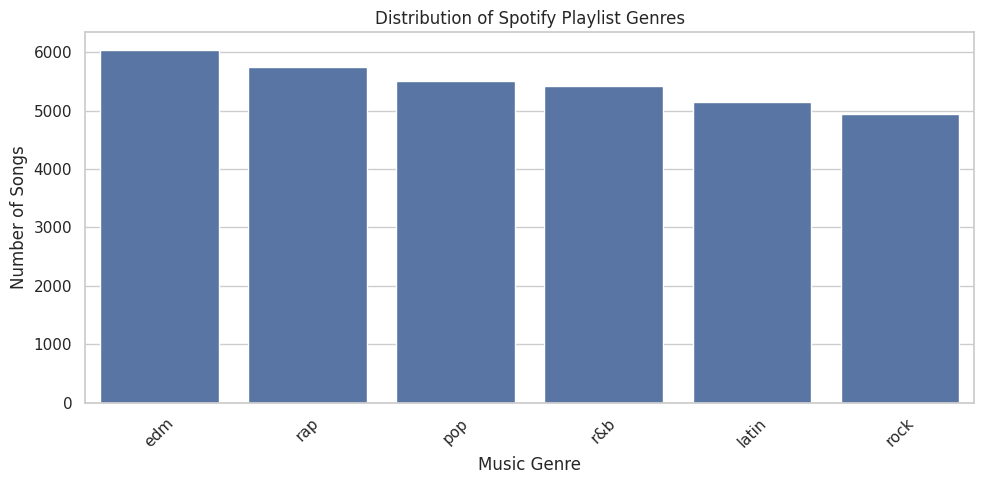

In [ ]:

plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x='playlist_genre',
    order=df['playlist_genre'].value_counts().index
)

plt.title("Distribution of Spotify Playlist Genres")
plt.xlabel("Music Genre")
plt.ylabel("Number of Songs")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


Audio features distribution

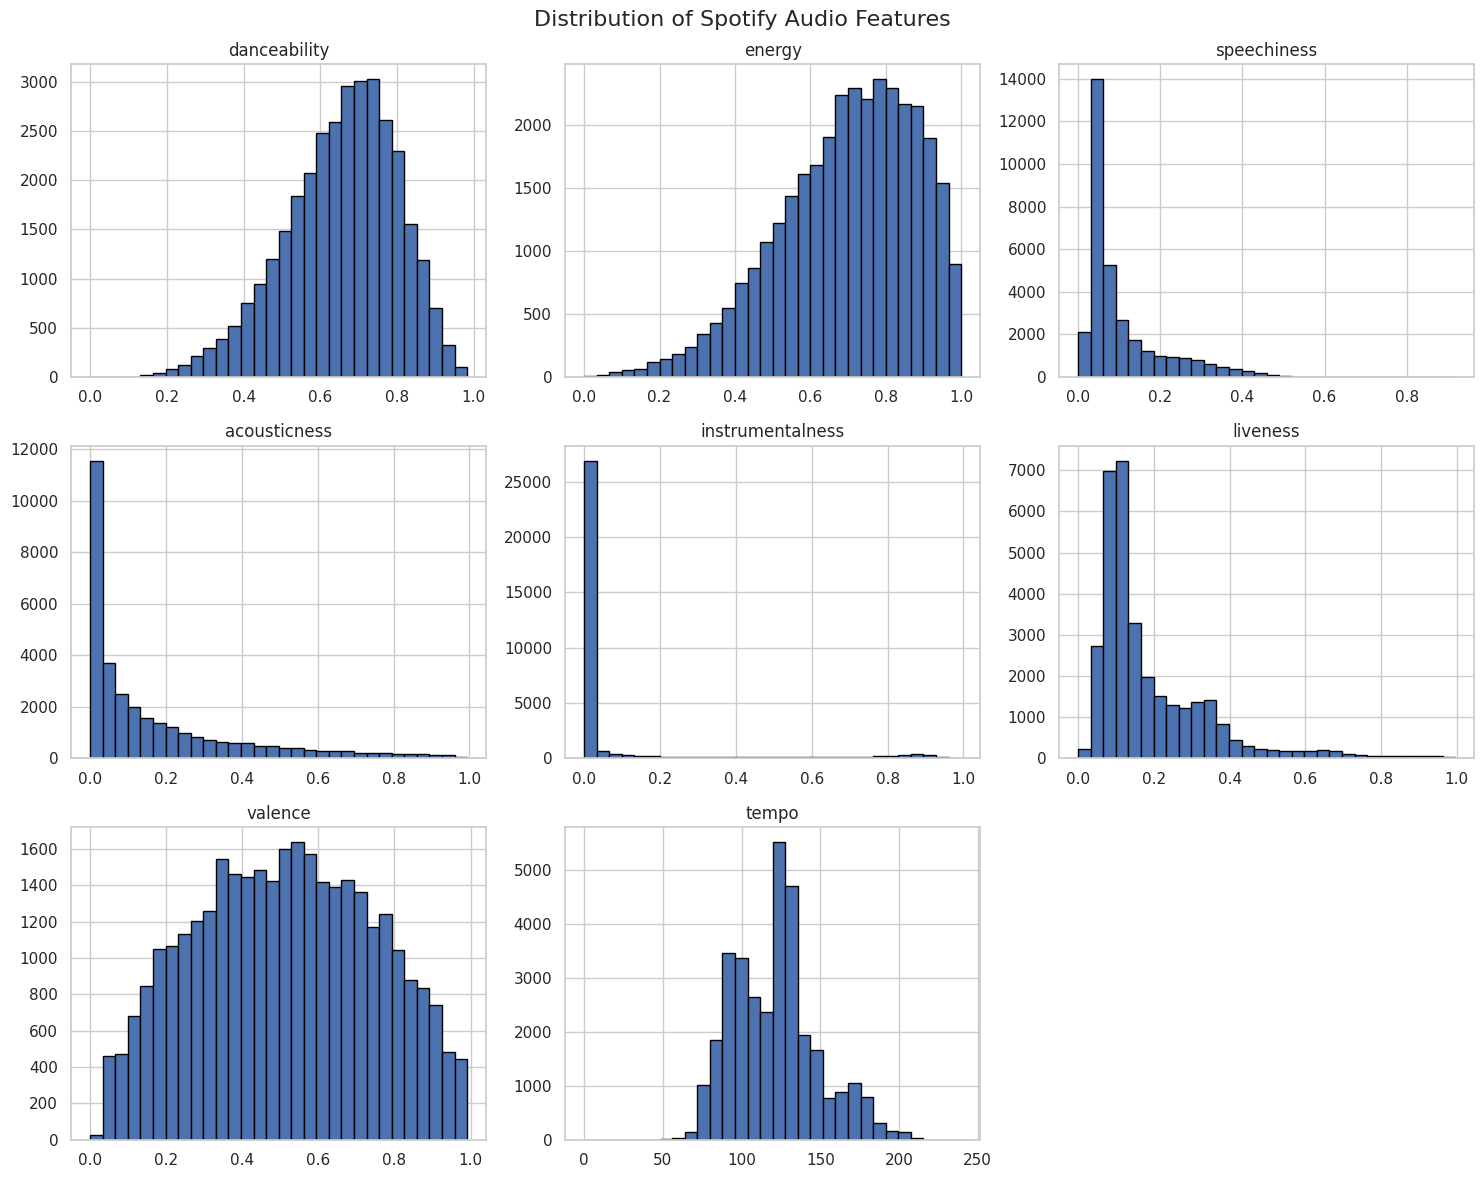

In [ ]:

audio_features = [
    'danceability',
    'energy',
    'speechiness',
    'acousticness',
    'instrumentalness',
    'liveness',
    'valence',
    'tempo'
]

df[audio_features].hist(
    figsize=(15, 12),
    bins=30,
    edgecolor='black'
)

plt.suptitle("Distribution of Spotify Audio Features", fontsize=16)
plt.tight_layout()
plt.show()


Popularity by genre

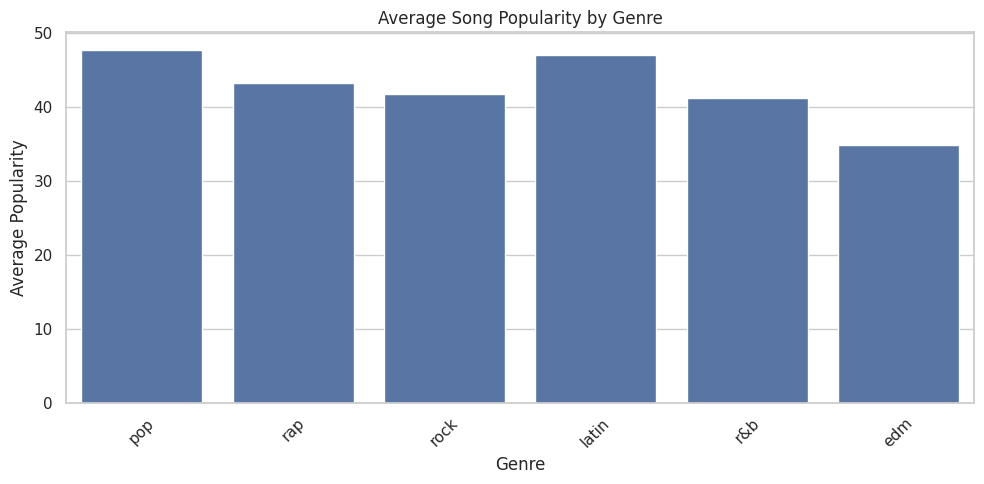

In [ ]:

plt.figure(figsize=(10, 5))

sns.barplot(
    data=df,
    x='playlist_genre',
    y='track_popularity',
    estimator='mean',
    errorbar=None
)

plt.title("Average Song Popularity by Genre")
plt.xlabel("Genre")
plt.ylabel("Average Popularity")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


Correlation matrix heatmap

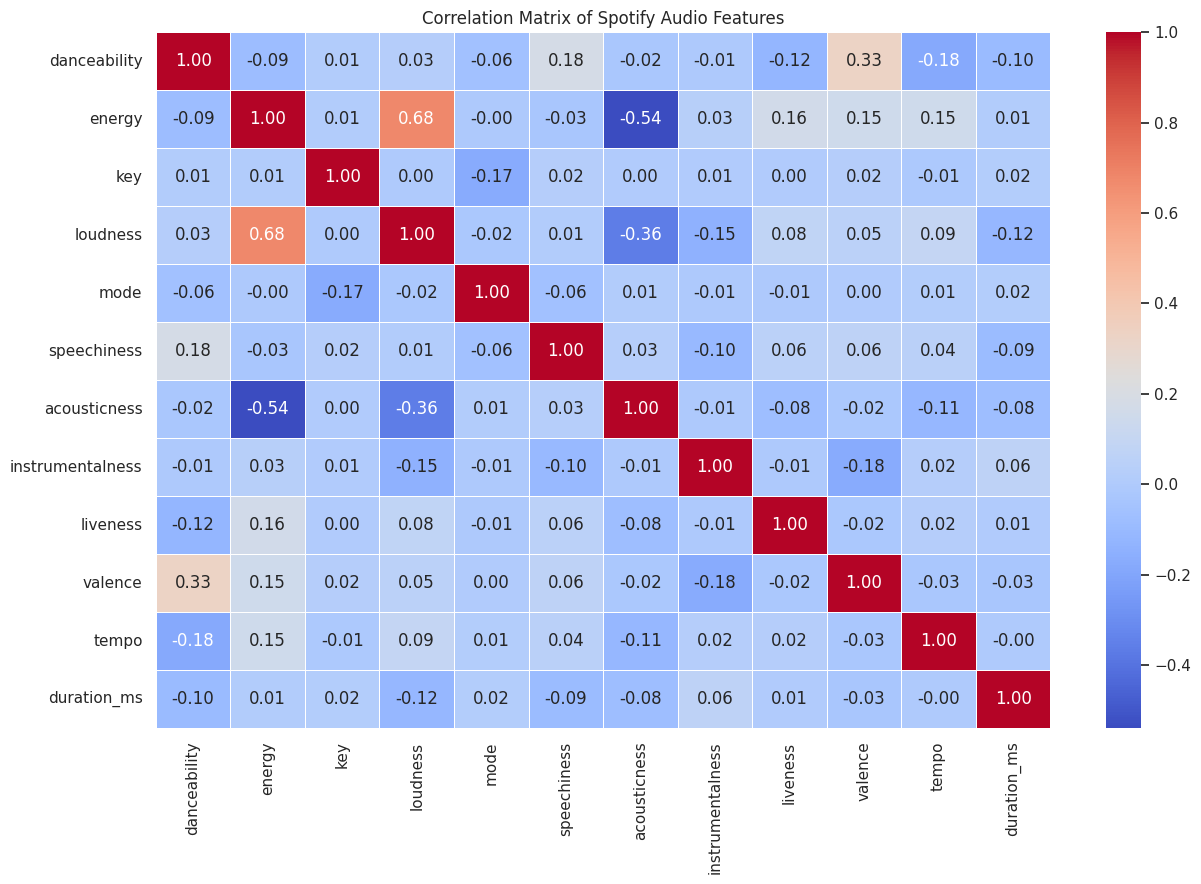

In [ ]:

plt.figure(figsize=(13, 9))

correlation = df[features].corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title("Correlation Matrix of Spotify Audio Features")
plt.tight_layout()
plt.show()


Identify outliers

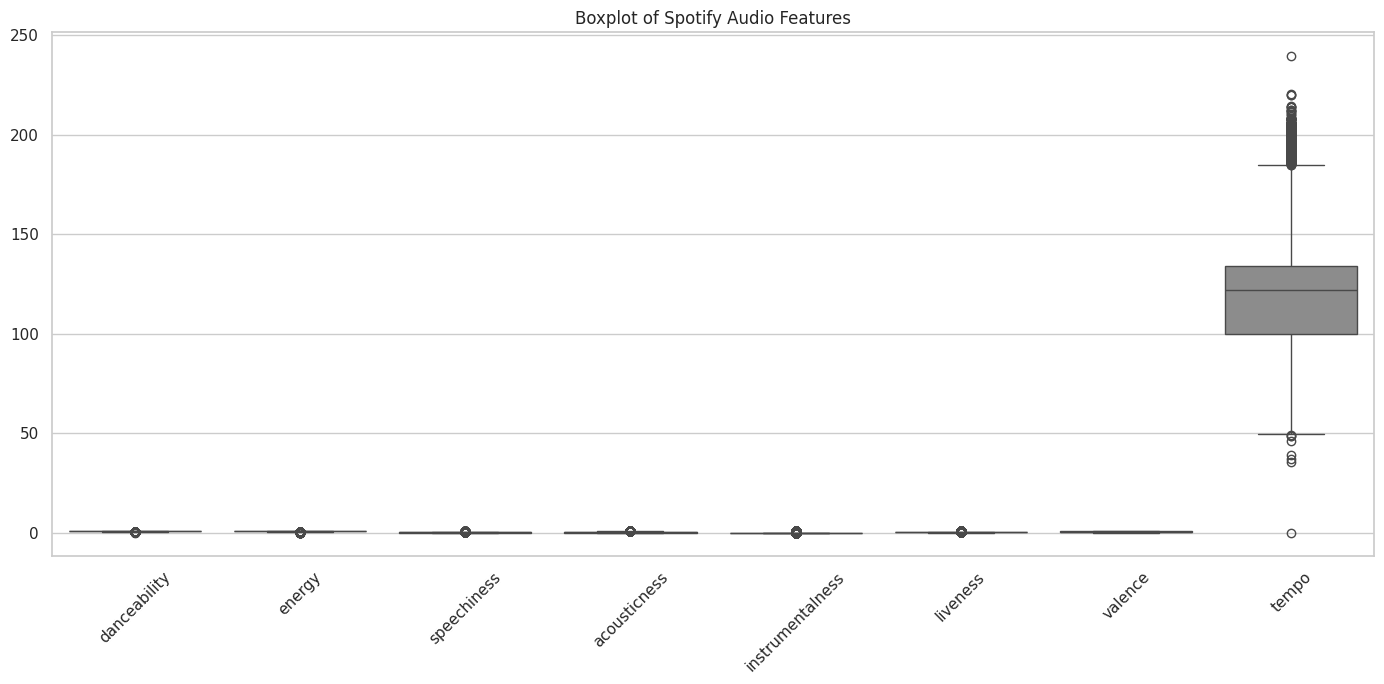

In [ ]:

plt.figure(figsize=(14, 7))

sns.boxplot(data=df[audio_features])

plt.title("Boxplot of Spotify Audio Features")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


Danceability vs Energy

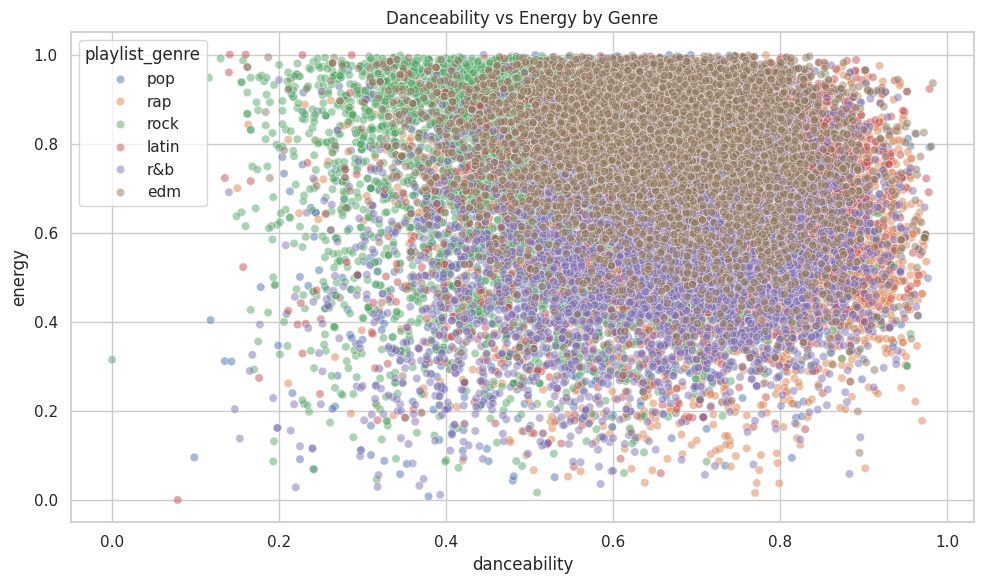

In [ ]:

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='danceability',
    y='energy',
    hue='playlist_genre',
    alpha=0.5
)

plt.title("Danceability vs Energy by Genre")
plt.tight_layout()
plt.show()


Playlist genre audio comparison

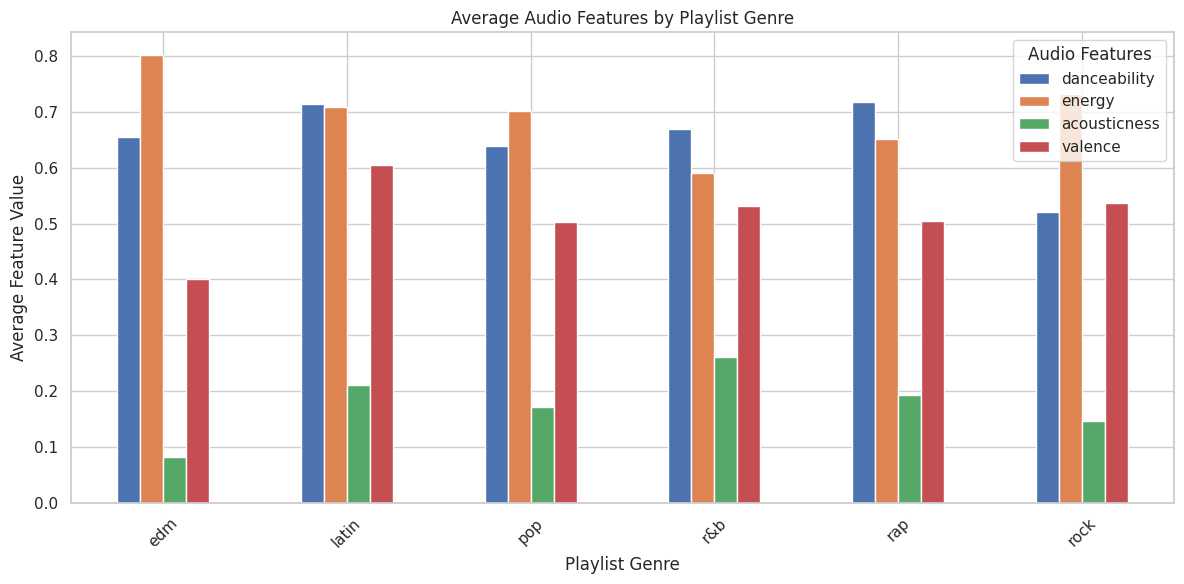

In [ ]:

genre_average = df.groupby('playlist_genre')[
    ['danceability', 'energy', 'acousticness', 'valence']
].mean()

genre_average.plot(
    kind='bar',
    figsize=(12, 6)
)

plt.title("Average Audio Features by Playlist Genre")
plt.xlabel("Playlist Genre")
plt.ylabel("Average Feature Value")
plt.xticks(rotation=45)
plt.legend(title="Audio Features")
plt.tight_layout()
plt.show()


Elbow Method

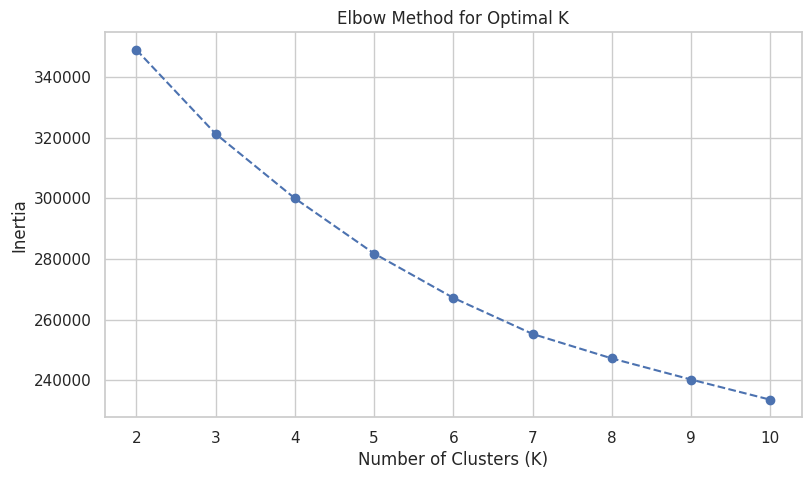

In [ ]:

from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

# Store inertia values
inertia = []

# Test different cluster numbers
K_range = range(2, 11)

for k in K_range:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

# Plot Elbow graph
plt.figure(figsize=(9, 5))

plt.plot(
    K_range,
    inertia,
    marker='o',
    linestyle='--'
)

plt.title("Elbow Method for Optimal K")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.xticks(K_range)
plt.grid(True)
plt.show()


Silhouette Score

K = 2, Silhouette Score = 0.1462
K = 3, Silhouette Score = 0.1002
K = 4, Silhouette Score = 0.1147
K = 5, Silhouette Score = 0.1076
K = 6, Silhouette Score = 0.1013
K = 7, Silhouette Score = 0.1063
K = 8, Silhouette Score = 0.1020
K = 9, Silhouette Score = 0.0978
K = 10, Silhouette Score = 0.1031


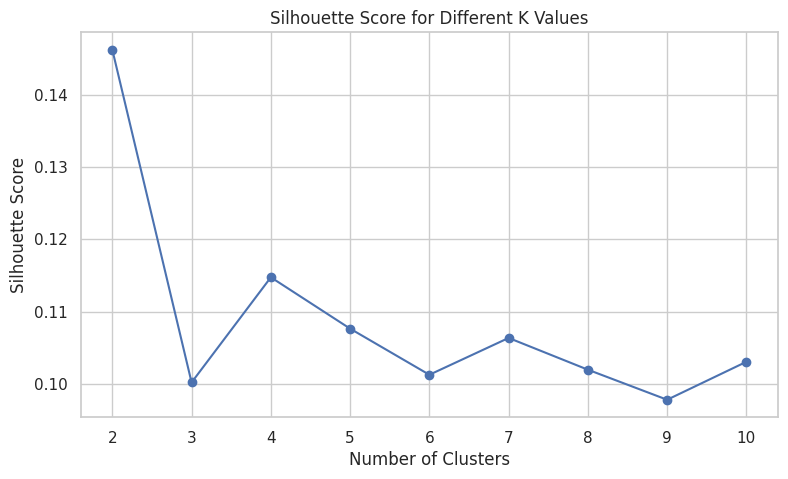

In [ ]:

from sklearn.metrics import silhouette_score
from sklearn.cluster import KMeans
import numpy as np

# Take a sample for faster evaluation
rng = np.random.RandomState(42)
sample_indices = rng.choice(
    len(X_scaled),
    size=min(5000, len(X_scaled)),
    replace=False
)

X_sample = X_scaled[sample_indices]

silhouette_scores = []

# Test K from 2 to 10
for k in range(2, 11):

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_sample)

    score = silhouette_score(
        X_sample,
        labels
    )

    silhouette_scores.append(score)

    print(f"K = {k}, Silhouette Score = {score:.4f}")

# Plot scores
plt.figure(figsize=(9, 5))

plt.plot(
    range(2, 11),
    silhouette_scores,
    marker='o'
)

plt.title("Silhouette Score for Different K Values")
plt.xlabel("Number of Clusters")
plt.ylabel("Silhouette Score")
plt.xticks(range(2, 11))
plt.grid(True)
plt.show()


final K-Means model

In [ ]:

# Build the final K-Means model

optimal_k = 6

kmeans_model = KMeans(
    n_clusters=optimal_k,
    random_state=42,
    n_init=10
)

# Train the model
cluster_labels = kmeans_model.fit_predict(X_scaled)

# Add cluster labels to original dataset
df['cluster'] = cluster_labels

print("K-Means Model Trained Successfully!")
print("Number of Clusters:", optimal_k)

# Display results
display(
    df[['track_name', 'track_artist',
        'playlist_genre', 'cluster']].head(10)
)


K-Means Model Trained Successfully!
Number of Clusters: 6


,track_name,track_artist,playlist_genre,cluster
0,I Don't Care (with Justin Bieber) - Loud Luxur...,Ed Sheeran,pop,0
1,Memories - Dillon Francis Remix,Maroon 5,pop,0
2,All the Time - Don Diablo Remix,Zara Larsson,pop,3
3,Call You Mine - Keanu Silva Remix,The Chainsmokers,pop,4
4,Someone You Loved - Future Humans Remix,Lewis Capaldi,pop,0
5,Beautiful People (feat. Khalid) - Jack Wins Remix,Ed Sheeran,pop,0
6,Never Really Over - R3HAB Remix,Katy Perry,pop,4
7,Post Malone (feat. RANI) - GATTÜSO Remix,Sam Feldt,pop,4
8,Tough Love - Tiësto Remix / Radio Edit,Avicii,pop,4
9,If I Can't Have You - Gryffin Remix,Shawn Mendes,pop,0


Visualize the clusters using PCA

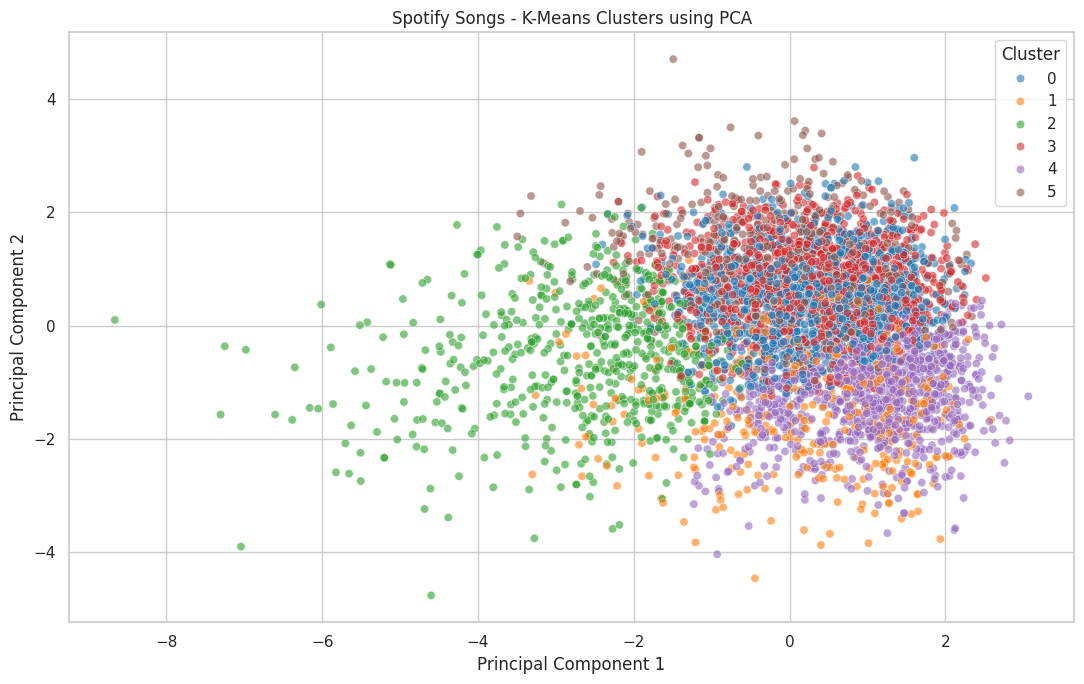

Variance explained by two components: 30.9 %


In [ ]:

from sklearn.decomposition import PCA

# Reduce 12 features to 2 dimensions
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

# Create visualization dataframe
pca_df = pd.DataFrame({
    'PCA1': X_pca[:, 0],
    'PCA2': X_pca[:, 1],
    'Cluster': cluster_labels
})

# Plot clusters
plt.figure(figsize=(11, 7))

sns.scatterplot(
    data=pca_df.sample(
        n=min(5000, len(pca_df)),
        random_state=42
    ),
    x='PCA1',
    y='PCA2',
    hue='Cluster',
    palette='tab10',
    alpha=0.6
)

plt.title("Spotify Songs - K-Means Clusters using PCA")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()

print(
    "Variance explained by two components:",
    round(pca.explained_variance_ratio_.sum() * 100, 2),
    "%"
)


Analyze clusters by playlist genre

Cluster Distribution by Genre:


playlist_genre,edm,latin,pop,r&b,rap,rock
cluster,,,,,,
0,1092,1989,1711,1340,1186,1243
1,1467,187,288,96,232,236
2,180,472,712,1379,596,842
3,1167,1657,1436,1415,1155,529
4,1906,374,1139,419,494,2069
5,231,476,221,782,2083,32


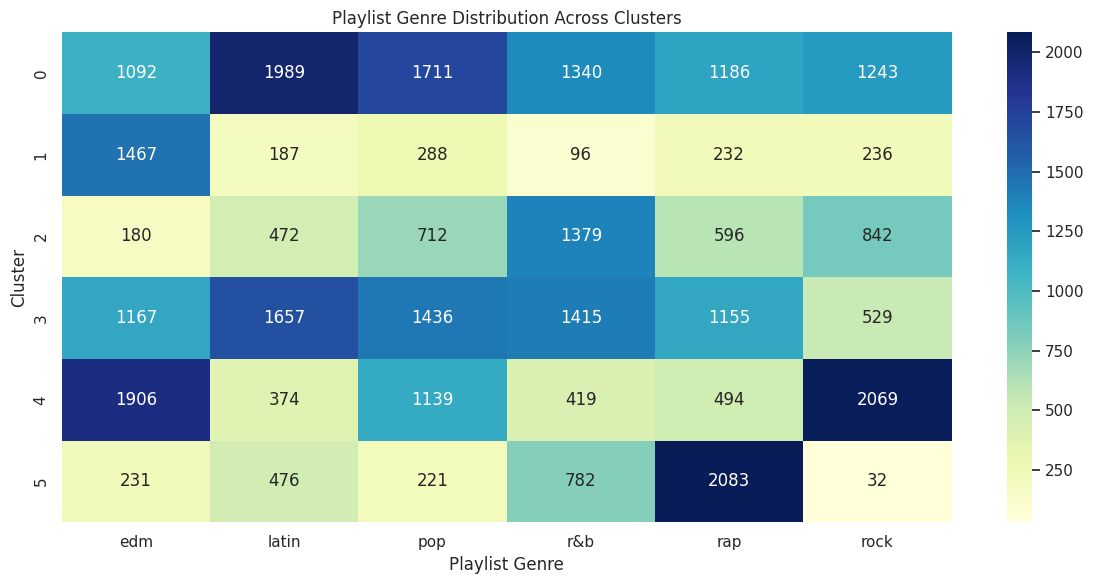

In [ ]:

# Count songs in each cluster by genre

genre_cluster = pd.crosstab(
    df['cluster'],
    df['playlist_genre']
)

print("Cluster Distribution by Genre:")
display(genre_cluster)

# Visualize
plt.figure(figsize=(12, 6))

sns.heatmap(
    genre_cluster,
    annot=True,
    fmt='d',
    cmap='YlGnBu'
)

plt.title("Playlist Genre Distribution Across Clusters")
plt.xlabel("Playlist Genre")
plt.ylabel("Cluster")
plt.tight_layout()
plt.show()


Analyze clusters by playlist name

In [ ]:

# Find the most common playlists in each cluster

for cluster_num in sorted(df['cluster'].unique()):

    print(f"\nCluster {cluster_num}")

    top_playlists = (
        df[df['cluster'] == cluster_num]
        ['playlist_name']
        .value_counts()
        .head(5)
    )

    print(top_playlists)



Cluster 0
playlist_name
Indie Poptimism                                   110
MIX LATIN POP°                                     85
2020 Hits & 2019  Hits – Top Global Tracks 🔥🔥🔥     81
Latin Pop antiguo                                  64
post teen pop                                      64
Name: count, dtype: int64

Cluster 1
playlist_name
Fitness Workout Electro | House | Dance | Progressive House                 93
Underground Party | Hypnotic | Minimal | Acid | Big Room | Tech | Liquid    89
House Electro 2019                                                          78
Selected House                                                              67
💊ELECTRO-HOUSE-TECH💊                                                        62
Name: count, dtype: int64

Cluster 2
playlist_name
Lush Lofi                                                    89
Urban contemporary                                           89
Lo-Fi Beats                                                  68
Ultimate Indie P

Evaluate the final model

In [ ]:

from sklearn.metrics import silhouette_score

# Evaluate using a sample of final model predictions
sample_labels = cluster_labels[sample_indices]

final_score = silhouette_score(
    X_sample,
    sample_labels
)

print("Final K-Means Model Evaluation")
print("--------------------------------")
print("Number of Clusters:", optimal_k)
print("Silhouette Score:", round(final_score, 4))
print("Total Songs Clustered:", len(df))

print("\nSongs in Each Cluster:")
print(df['cluster'].value_counts().sort_index())


Final K-Means Model Evaluation
--------------------------------
Number of Clusters: 6
Silhouette Score: 0.1011
Total Songs Clustered: 32833

Songs in Each Cluster:
cluster
0    8561
1    2506
2    4181
3    7359
4    6401
5    3825
Name: count, dtype: int64


Train the K-Means model

In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Select the best K from your experiments
optimal_k = 2

# Train the final K-Means model
kmeans_model = KMeans(
    n_clusters=optimal_k,
    random_state=42,
    n_init=10
)

# Assign clusters to songs
cluster_labels = kmeans_model.fit_predict(X_scaled)

# Add cluster numbers to the dataset
df['cluster'] = cluster_labels

print("Final Model Training Completed!")
print("Optimal K:", optimal_k)
print("Cluster Counts:")
print(df['cluster'].value_counts())

Final Model Training Completed!
Optimal K: 2
Cluster Counts:
cluster
0    23211
1     9622
Name: count, dtype: int64


In [ ]:
# Reset the index without changing row order
df = df.reset_index(drop=True)

print("Dataset is ready!")
print("Total songs:", len(df))
print("Total clusters:", df['cluster'].nunique())

Dataset is ready!
Total songs: 32833
Total clusters: 2


function

In [ ]:
import numpy as np

def recommend_songs(song_name, top_n=10):

    # Search for the entered song
    matches = df[
        df['track_name'].str.contains(
            song_name, case=False, na=False
        )
    ]

    if matches.empty:
        print("Song not found! Try another song name.")
        return

    # Select the first matching song
    chosen_pos = matches.index[0]
    chosen_song = df.iloc[chosen_pos]

    # Find the cluster of the selected song
    chosen_cluster = chosen_song['cluster']

    print("Selected Song:", chosen_song['track_name'])
    print("Artist:", chosen_song['track_artist'])
    print("Cluster:", chosen_cluster)

    # Find songs belonging to the same cluster
    cluster_mask = (
        df['cluster'].to_numpy() == chosen_cluster
    )

    candidate_positions = np.where(cluster_mask)[0]

    # Exclude the selected song
    candidate_positions = candidate_positions[
        candidate_positions != chosen_pos
    ]

    # Exclude other playlist copies of the same track
    candidate_positions = candidate_positions[
        df.iloc[candidate_positions]['track_id'].to_numpy()
        != chosen_song['track_id']
    ]

    if len(candidate_positions) == 0:
        print("No similar songs found.")
        return

    # Calculate distances between audio features
    distances = np.linalg.norm(
        X_scaled[candidate_positions] - X_scaled[chosen_pos],
        axis=1
    )

    # Select the closest songs
    best_positions = candidate_positions[
        np.argsort(distances)[:top_n]
    ]

    # Display recommendations
    recommendations = df.iloc[best_positions][
        [
            'track_name',
            'track_artist',
            'playlist_genre',
            'track_popularity'
        ]
    ]

    print("\nRecommended Songs:")
    display(recommendations)

Test my recommendation system

In [ ]:
recommend_songs("Shape of You", 10)

Selected Song: Shape of You
Artist: Ed Sheeran
Cluster: 0

Recommended Songs:


,track_name,track_artist,playlist_genre,track_popularity
17488,Shape of You,Ed Sheeran,latin,75
23867,Shape of You,Ed Sheeran,r&b,75
4611,in my miNd,Maty Noyes,pop,58
21941,On The Low,Burna Boy,r&b,74
16372,Donde Estabas Anoche,Aymee Nuviola,latin,44
19024,El Efecto,Rauw Alejandro,latin,78
2825,Baby I'm Yours - feat. Irfane,Breakbot,pop,71
22634,Es Tu Mirada - Remasterizado,Leoni Torres,r&b,49
16915,Cara de Niño,Jonathan Moly,latin,42
11767,Beast Of Burden - Remastered,The Rolling Stones,rock,18


Save my project files

In [ ]:
import joblib
import numpy as np

# Save processed dataset
df.to_csv("spotify_songs_clustered.csv", index=False)

# Save trained K-Means model
joblib.dump(kmeans_model, "kmeans_model.pkl")

# Save scaler
joblib.dump(scaler, "scaler.pkl")

# Save scaled audio features
np.save("scaled_audio_features.npy", X_scaled)

print("All project files saved successfully!")

All project files saved successfully!


Create a Python file

In [ ]:
%%writefile app.py

import streamlit as st
import pandas as pd
import numpy as np
import joblib

# Load saved files
df = pd.read_csv("spotify_songs_clustered.csv")
kmeans_model = joblib.load("kmeans_model.pkl")
scaler = joblib.load("scaler.pkl")
X_scaled = np.load("scaled_audio_features.npy")

# Page settings
st.set_page_config(
    page_title="Spotify Song Recommendation",
    page_icon="🎵",
    layout="wide"
)

st.title("🎵 Spotify Song Recommendation System")

st.write(
    "Discover songs similar to your favourite Spotify tracks "
    "using Machine Learning and K-Means Clustering."
)

# Song selection
song_list = sorted(
    df["track_name"].dropna().unique().tolist()
)

selected_song = st.selectbox(
    "Choose a song",
    song_list
)

if st.button("Get Recommendations"):

    matches = df[
        df["track_name"] == selected_song
    ]

    chosen_pos = matches.index[0]
    chosen = df.iloc[chosen_pos]

    st.subheader("Selected Song")

    st.write("**Song:**", chosen["track_name"])
    st.write("**Artist:**", chosen["track_artist"])
    st.write("**Genre:**", chosen["playlist_genre"])

    # Find songs in the same cluster
    cluster = chosen["cluster"]

    candidates = np.where(
        df["cluster"].to_numpy() == cluster
    )[0]

    # Remove selected song and duplicate copies
    candidates = candidates[candidates != chosen_pos]

    candidates = candidates[
        df.iloc[candidates]["track_id"].to_numpy()
        != chosen["track_id"]
    ]

    # Calculate distances
    distances = np.linalg.norm(
        X_scaled[candidates] - X_scaled[chosen_pos],
        axis=1
    )

    # Find closest songs
    best = candidates[np.argsort(distances)[:10]]

    recommendations = df.iloc[best][
        [
            "track_name",
            "track_artist",
            "playlist_genre",
            "track_popularity"
        ]
    ].reset_index(drop=True)

    recommendations.index += 1

    st.subheader("🎧 Recommended Songs")
    st.dataframe(recommendations, use_container_width=True)

    st.success("Recommendations generated successfully!")

Writing app.py


Create requirements.txt

In [ ]:
%%writefile requirements.txt

streamlit
pandas
numpy
scikit-learn
joblib

Writing requirements.txt


In [ ]:
import os

print(os.listdir())

['.config', 'app.py', 'spotify_songs_clustered.csv', 'scaler.pkl', 'kmeans_model.pkl', 'requirements.txt', 'scaled_audio_features.npy', 'sample_data']


In [ ]:
from google.colab import files
import os

project_files = [
    "app.py",
    "requirements.txt",
    "spotify_songs_clustered.csv",
    "kmeans_model.pkl",
    "scaler.pkl",
    "scaled_audio_features.npy"
]

for file in project_files:
    files.download(file)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

... (2 outputs left out)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import sys
import joblib
import sklearn

print("Python Version:", sys.version)
print("Joblib Version:", joblib.__version__)
print("Scikit-learn Version:", sklearn.__version__)

Python Version: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
Joblib Version: 1.6.0
Scikit-learn Version: 1.6.1


Check my files